In [9]:
import pandas as pd
import numpy as np
from pathlib import Path
import seaborn as sns
import geopandas as gpd
import matplotlib.pyplot as plt
BASE_DIR = Path.cwd().resolve().parent
BASE_DIR

DATA_DIR = BASE_DIR / "data" / "2025"
RAW_DIR = DATA_DIR / "raw"/ "2025"

ruta_mapa = BASE_DIR/ "data"/"geo"/"LIM_DEPARTAMENTAL_PERU_MIN.json"

peru = gpd.read_file(ruta_mapa)

ruta_parquet = BASE_DIR/"data"/"raw"/"2025"/"01_CARATULA.parquet"

datos = pd.read_parquet(ruta_parquet)


In [3]:
datos.info()

<class 'pandas.DataFrame'>
RangeIndex: 41164 entries, 0 to 41163
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ANIO              41164 non-null  int64  
 1   CCDD              39485 non-null  float64
 2   NOMBREDD          39485 non-null  str    
 3   CCPP              39485 non-null  float64
 4   NOMBREPV          39485 non-null  str    
 5   CCDI              39485 non-null  float64
 6   NOMBREDI          39485 non-null  str    
 7   NSEGM             41164 non-null  int64  
 8   ID_PROD           41164 non-null  int64  
 9   UA                41164 non-null  int64  
 10  RESFIN            41164 non-null  int64  
 11  REGION            41164 non-null  int64  
 12  ESTRATO           38457 non-null  float64
 13  FACTOR_PRODUCTOR  40136 non-null  float64
 14  CODIGO            41164 non-null  int64  
 15  LATITUD           39485 non-null  float64
 16  LONGITUD          39485 non-null  float64
dtypes: f

In [16]:
df_CARATULA = pd.read_parquet(RAW_DIR / "01_CARATULA.parquet")
df_cap200b = pd.read_parquet(RAW_DIR / "04_CAP200B_1.parquet")

In [13]:
df_CARATULA.info(verbose = True)

<class 'pandas.DataFrame'>
RangeIndex: 41164 entries, 0 to 41163
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ANIO              41164 non-null  int64  
 1   CCDD              39485 non-null  float64
 2   NOMBREDD          39485 non-null  str    
 3   CCPP              39485 non-null  float64
 4   NOMBREPV          39485 non-null  str    
 5   CCDI              39485 non-null  float64
 6   NOMBREDI          39485 non-null  str    
 7   NSEGM             41164 non-null  int64  
 8   ID_PROD           41164 non-null  int64  
 9   UA                41164 non-null  int64  
 10  RESFIN            41164 non-null  int64  
 11  REGION            41164 non-null  int64  
 12  ESTRATO           38457 non-null  float64
 13  FACTOR_PRODUCTOR  40136 non-null  float64
 14  CODIGO            41164 non-null  int64  
 15  LATITUD           39485 non-null  float64
 16  LONGITUD          39485 non-null  float64
dtypes: f

In [21]:
df_cap200b.info(verbose = True)

<class 'pandas.DataFrame'>
RangeIndex: 6021 entries, 0 to 6020
Data columns (total 33 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ANIO              6021 non-null   int64  
 1   CCDD              5984 non-null   float64
 2   NOMBREDD          5984 non-null   str    
 3   CCPP              5984 non-null   float64
 4   NOMBREPV          5984 non-null   str    
 5   CCDI              5984 non-null   float64
 6   NOMBREDI          5984 non-null   str    
 7   NSEGM             6021 non-null   int64  
 8   ID_PROD           6021 non-null   int64  
 9   UA                6021 non-null   int64  
 10  RESFIN            6021 non-null   int64  
 11  REGION            6021 non-null   int64  
 12  ESTRATO           5984 non-null   float64
 13  FACTOR_PRODUCTOR  6021 non-null   float64
 14  CODIGO            6021 non-null   int64  
 15  P101A             37 non-null     float64
 16  P142_1            6021 non-null   int64  
 17  P142_2

In [45]:
provincias = provincias_peru.copy()
provincias_ama = provincias_peru[
    provincias_peru["NOMBDEP"].str.upper().eq("AMAZONAS")
]

provincias_ama.head(5)

,OBJECTID_1,OBJECTID,CCDD,NOMBDEP,CCPP,NOMBPROV,CAPITAL,IDPROV,Shape_STAr,Shape_STLe,ORIG_FID,Shape_Leng,Shape_Area,geometry
100,111,101,01,AMAZONAS,02,BAGUA,BAGUA,0102,0.472370,4.294658,100,4.294658,0.472370,"POLYGON ((-78.10615 -5.342, -78.09676 -5.34128..."
101,112,102,01,AMAZONAS,03,BONGARA,JUMBILLA,0103,0.231319,3.038661,101,3.038661,0.231319,"POLYGON ((-77.69596 -5.41105, -77.70279 -5.380..."
102,113,103,01,AMAZONAS,01,CHACHAPOYAS,CHACHAPOYAS,0101,0.237605,3.872238,102,3.872238,0.237605,"POLYGON ((-77.67167 -5.9741, -77.68756 -5.9791..."
103,114,104,01,AMAZONAS,04,CONDORCANQUI,SANTA MARIA DE NIEVA,0104,1.455241,7.617350,103,7.617350,1.455241,"POLYGON ((-77.74529 -5.13302, -77.76757 -5.111..."
104,115,105,01,AMAZONAS,05,LUYA,LAMUD,0105,0.270145,2.868283,104,2.868283,0.270145,"POLYGON ((-77.89095 -6.10269, -77.90392 -6.092..."


In [46]:
df_amazonas = df_cap200b[df_cap200b["NOMBREDD"]=="AMAZONAS"].copy()

EN LOS ÚLTIMOS 12 MESES, DE…..A LA EMPRESA/UD. REALIZÓ ACTIVIDAD: ¿Agrícola? o ¿Pecuaria?

In [88]:
cols_p142 = ["P142_1", "P142_2"]

df_amazonas[cols_p142] = df_amazonas[cols_p142].apply(
    pd.to_numeric,
    errors="coerce"
)

sub_ama = df_amazonas[cols_p142]

In [98]:
nombres_actividades = [
    "Actividad Agrícola",
    "Actividad Pecuaria"
]

tabla_p142_ama = pd.DataFrame({
    "actividad": nombres_actividades,
    "si_realizo": [sub_ama[c].eq(1).sum() for c in cols_p142],
    "no_realizo": [sub_ama[c].eq(0).sum() for c in cols_p142]
})

tabla_p142_ama

,actividad,si_realizo,no_realizo
0,Actividad Agrícola,87,0
1,Actividad Pecuaria,68,19


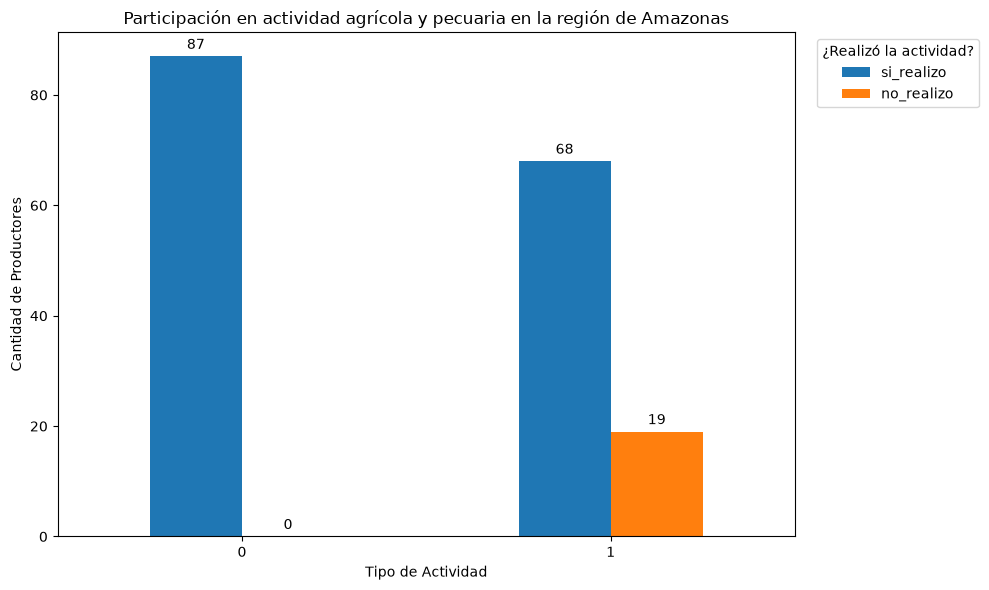

In [109]:
gr_reg_tipo_ama = tabla_p142_ama.plot(
    kind="bar",
    stacked=False,
    figsize=(10, 6),
)

gr_reg_tipo_ama.set_title("Participación en actividad agrícola y pecuaria en la región de Amazonas")
gr_reg_tipo_ama.set_xlabel("Tipo de Actividad")
gr_reg_tipo_ama.set_ylabel("Cantidad de Productores")  

gr_reg_tipo_ama.legend(
    title="¿Realizó la actividad?",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

for container in gr_reg_tipo_ama.containers:
    gr_reg_tipo_ama.bar_label(
        container,
        fmt="%d",
        label_type="edge",  
        padding=3,          
        fontsize=10
    )

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

NÚMERO DE PARCELA O CHACRA QUE TRABAJÓ O CONDUJO EN LOS ÚLTIMOS 12 MESES

In [100]:
df_amazonas["P147"] = pd.to_numeric(df_amazonas["P147"], errors="coerce")

tabla_p147_ama = df_amazonas["P147"].value_counts().reset_index()
tabla_p147_ama.columns = ["numero_parcela", "cantidad_productores"]

tabla_p147_ama = tabla_p147_ama.sort_values("numero_parcela").reset_index(drop=True)

tabla_p147_ama   # corregir

,numero_parcela,cantidad_productores
0,1,50
1,2,23
2,3,9
3,4,3
4,5,1
5,7,1


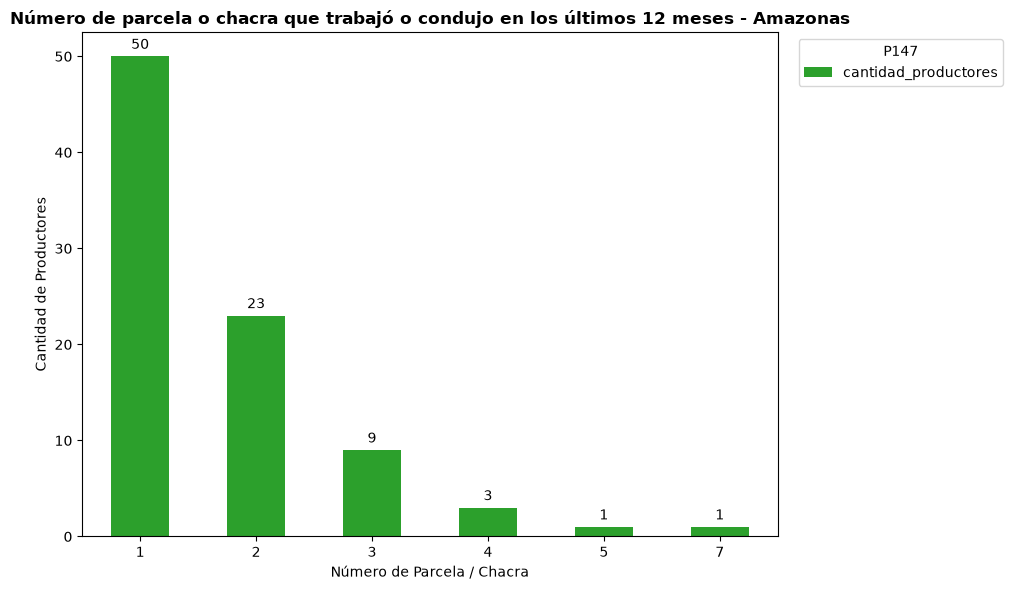

In [110]:
df_grafico_p147 = tabla_p147_ama.set_index("numero_parcela")[["cantidad_productores"]]

gr_p147_ama = df_grafico_p147.plot(
    kind="bar",
    stacked=False,
    figsize=(10, 6),
    color="#2ca02c"
)

gr_p147_ama.set_title("Número de parcela o chacra que trabajó o condujo en los últimos 12 meses - Amazonas", fontsize=12, fontweight="bold")
gr_p147_ama.set_xlabel("Número de Parcela / Chacra", fontsize=10)
gr_p147_ama.set_ylabel("Cantidad de Productores", fontsize=10)  

gr_p147_ama.legend(
    title="P147",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

for container in gr_p147_ama.containers:
    gr_p147_ama.bar_label(
        container,
        fmt="%d",
        label_type="edge",  
        padding=3,          
        fontsize=10
    )

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#cultivos que sufrieron pérdida total de producción o superficie

In [102]:
df_ama_p224b = df_amazonas.dropna(subset=["P224B_NOM"])

tabla_p224b_ama = df_ama_p224b["P224B_NOM"].value_counts().reset_index()
tabla_p224b_ama.columns = ["cultivo_afectado", "cantidad_casos"]

tabla_p224b_ama = tabla_p224b_ama.sort_values("cantidad_casos", ascending=False).reset_index(drop=True)

tabla_p224b_ama

,cultivo_afectado,cantidad_casos
0,MAIZ AMARILLO DURO,17
1,PLATANO,13
2,ARROZ CASCARA,10
3,FRIJOL PINTO,6
4,CAFE PERGAMINO,6
5,NARANJO,4
6,MAIZ AMILACEO,3
7,YUCA,3
8,PAPA BLANCA,2
9,FRIJOL SHINGO,2


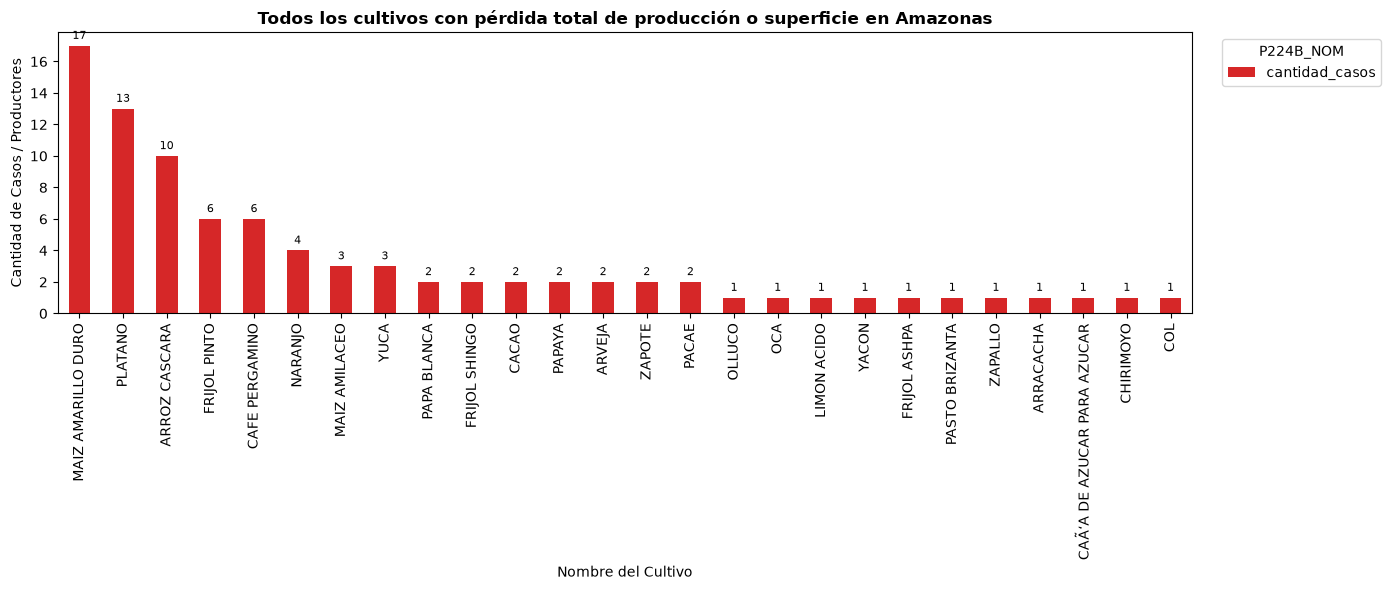

In [111]:
df_grafico_p224b = tabla_p224b_ama.set_index("cultivo_afectado")[["cantidad_casos"]]

gr_p224b_ama = df_grafico_p224b.plot(
    kind="bar",
    stacked=False,
    figsize=(14, 6),
    color="#d62728"
)

gr_p224b_ama.set_title("Todos los cultivos con pérdida total de producción o superficie en Amazonas", fontsize=12, fontweight="bold")
gr_p224b_ama.set_xlabel("Nombre del Cultivo", fontsize=10)
gr_p224b_ama.set_ylabel("Cantidad de Casos / Productores", fontsize=10)  

gr_p224b_ama.legend(
    title="P224B_NOM",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

for container in gr_p224b_ama.containers:
    gr_p224b_ama.bar_label(
        container,
        fmt="%d",
        label_type="edge", 
        padding=3,          
        fontsize=8        
    )

plt.xticks(rotation=90, ha="center")
plt.tight_layout()
plt.show()  # porcentaje 

#¿CUÁL FUE LA SUPERFICIE SEMBRADA/INSTALADA DE ?

In [112]:
cols_sup = ["P224D_SUP_1", "P224D_SUP_2"]

df_amazonas[cols_sup] = df_amazonas[cols_sup].apply(pd.to_numeric, errors="coerce")

df_amazonas["SUPERFICIE_TOTAL"] = df_amazonas["P224D_SUP_1"] + (df_amazonas["P224D_SUP_2"])

tabla_sup_ama = df_amazonas.groupby("NOMBREPV")[["SUPERFICIE_TOTAL"]].sum().reset_index()
tabla_sup_ama.columns = ["provincia", "superficie_total"]

tabla_sup_ama

,provincia,superficie_total
0,BAGUA,83.65
1,BONGARA,36.23
2,CHACHAPOYAS,12.81
3,CONDORCANQUI,27.50
4,LUYA,12.79
5,RODRIGUEZ DE MENDOZA,0.50
6,UTCUBAMBA,138.21


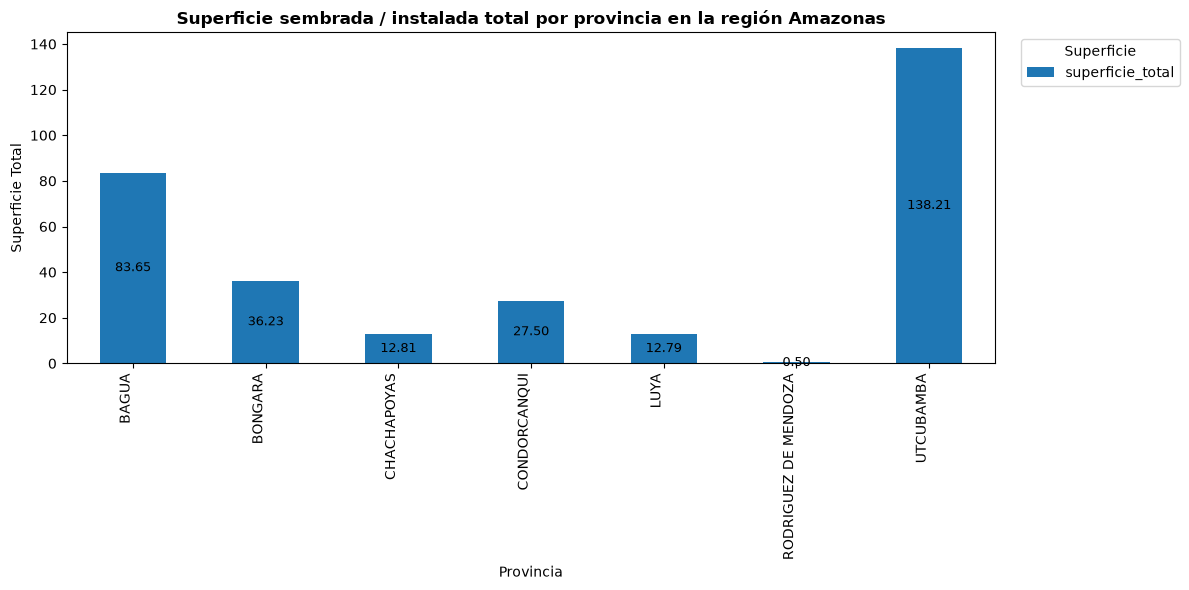

In [114]:
df_grafico_sup = tabla_sup_ama.set_index("provincia")[["superficie_total"]]

gr_sup_ama = df_grafico_sup.plot(
    kind="bar",
    stacked=False,
    figsize=(12, 6),
    color="#1f77b4" # Color azul corporativo
)

gr_sup_ama.set_title("Superficie sembrada / instalada total por provincia en la región Amazonas", fontsize=12, fontweight="bold")
gr_sup_ama.set_xlabel("Provincia", fontsize=10)
gr_sup_ama.set_ylabel("Superficie Total", fontsize=10)  

gr_sup_ama.legend(
    title="Superficie",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
# Agregar las etiquetas con los valores dentro de cada barra
for container in gr_sup_ama.containers:
    gr_sup_ama.bar_label(
        container,
        fmt="%.2f", 
        label_type="center",
        fontsize=9
    )

plt.xticks(rotation=90, ha="right")
plt.tight_layout()
plt.show()

In [62]:
resumen_tipo_cultivo_ama = (
    df_amazonas
    .groupby(["NOMBREDD", "P147"])
    .size()
    .reset_index(name="cantidad")
)

resumen_tipo_cultivo_ama.head(10)

,NOMBREDD,P147,cantidad
0,AMAZONAS,1,50
1,AMAZONAS,2,23
2,AMAZONAS,3,9
3,AMAZONAS,4,3
4,AMAZONAS,5,1
5,AMAZONAS,7,1


.EN QUE CULTIVOS SEMBRADOS/INSTALADOS TUVO PERDIDA TOTAL DE PRODUCCIÓN O SUPERFICIE EN AMAZONAS?

In [72]:
resumen_tipo_cultivo_ama = pd.crosstab(
    df_amazonas["NOMBREPV"],
    df_amazonas["P224B_TIPO"],
    normalize = "index",
)*100
resumen_tipo_cultivo_ama = resumen_tipo_cultivo_lam.round(2)
resumen_tipo_cultivo_ama = resumen_tipo_cultivo_lam.rename(columns={
    "1": "Transitorio",
    "2": "Permanente_Estacional",
    "3": "Permanente_Continua"
})
resumen_tipo_cultivo_ama

P224B_TIPO,1,2,3
NOMBREPV,,,
BAGUA,45.45,18.18,36.36
BONGARA,83.33,16.67,0.00
CHACHAPOYAS,100.00,0.00,0.00
CONDORCANQUI,0.00,0.00,100.00
LUYA,66.67,33.33,0.00
RODRIGUEZ DE MENDOZA,0.00,100.00,0.00
UTCUBAMBA,62.86,20.00,17.14


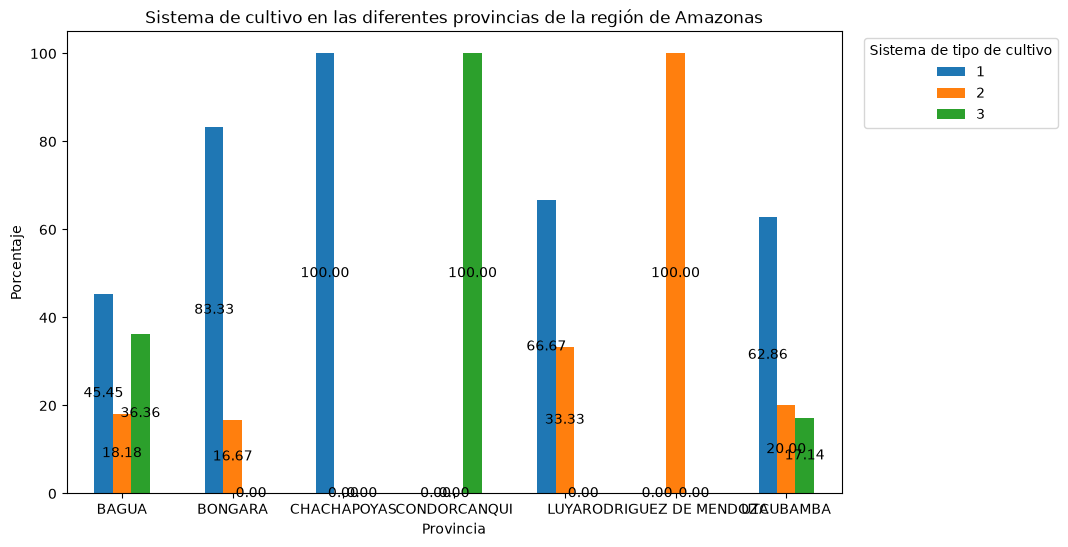

In [115]:
gr_reg_tipo_ama = resumen_tipo_cultivo_ama.plot(
    kind = "bar",
    stacked = False,
    figsize = (10, 6)
)
gr_reg_tipo_ama.set_title("Sistema de cultivo en las diferentes provincias de la región de Amazonas")
gr_reg_tipo_ama.set_xlabel("Provincia")
gr_reg_tipo_ama.set_ylabel("Porcentaje")  

gr_reg_tipo_ama.legend(
    title = "Sistema de tipo de cultivo",
    bbox_to_anchor = (1.02, 1),
    loc = "upper left"
)

for container in gr_reg_tipo_ama.containers:
    gr_reg_tipo_ama.bar_label(
        container,
        fmt = "%.2f",
        label_type = "center",
        fontsize = 10
    )
plt.xticks(rotation = 0)
plt.show()

¿CUÁL FUE EL MOTIVO DE LA PÉRDIDA TOTAL DE PRODUCCIÓN O SUPERFICIE EN AMAZONAS? 

In [73]:
df_cap200b["P224E_1"].value_counts(dropna=False)

P224E_1
0    5832
1     189
Name: count, dtype: int64

In [74]:
df_cap200b["P224E_2"].value_counts(dropna=False)

P224E_2
0    4071
1    1950
Name: count, dtype: int64

In [75]:
df_cap200b["P224E_3"].value_counts(dropna=False)

P224E_3
0    3486
1    2535
Name: count, dtype: int64

In [76]:
df_cap200b["P224E_4"].value_counts(dropna=False)

P224E_4
0    3087
1    2934
Name: count, dtype: int64

In [77]:
df_cap200b["P224E_5"].value_counts(dropna=False)

P224E_5
0    4173
1    1848
Name: count, dtype: int64

In [78]:
df_cap200b["P224E_6"].value_counts(dropna=False)

P224E_6
0    5141
1     880
Name: count, dtype: int64

In [79]:
df_cap200b["P224E_7"].value_counts(dropna=False)

P224E_7
0    5548
1     473
Name: count, dtype: int64

In [81]:
cols_factores = [f"P224E_{i}" for i in range(1, 8)]

df_amazonas[cols_factores] = df_amazonas[cols_factores].apply(
    pd.to_numeric,
    errors="coerce"
)

factores_ama = df_amazonas[cols_factores]

nombres_factores = [
    "huaycos, deslizamientos o derrumbes",
    "inundaciones",
    "plagas y/o emfermedades",
    "heladas",
    "granizada",
    "sequia",
    "Otros"
]

tabla_ama = pd.DataFrame({
    "factor": nombres_factores,
    "si_afecto": [factores_ama[c].eq(1).sum() for c in cols_factores],
    "no_afecto": [factores_ama[c].eq(0).sum() for c in cols_factores]
})

tabla_ama["porcentaje_falla"] = (
    tabla_ama["si_afecto"] /
    (tabla_ama["si_afecto"] + tabla_ama["no_afecto"]) * 100
).round(2)

tabla_ama

,factor,si_afecto,no_afecto,porcentaje_falla
0,"huaycos, deslizamientos o derrumbes",8,79,9.20
1,inundaciones,14,73,16.09
2,plagas y/o emfermedades,24,63,27.59
3,heladas,2,85,2.30
4,granizada,0,87,0.00
5,sequia,54,33,62.07
6,Otros,5,82,5.75


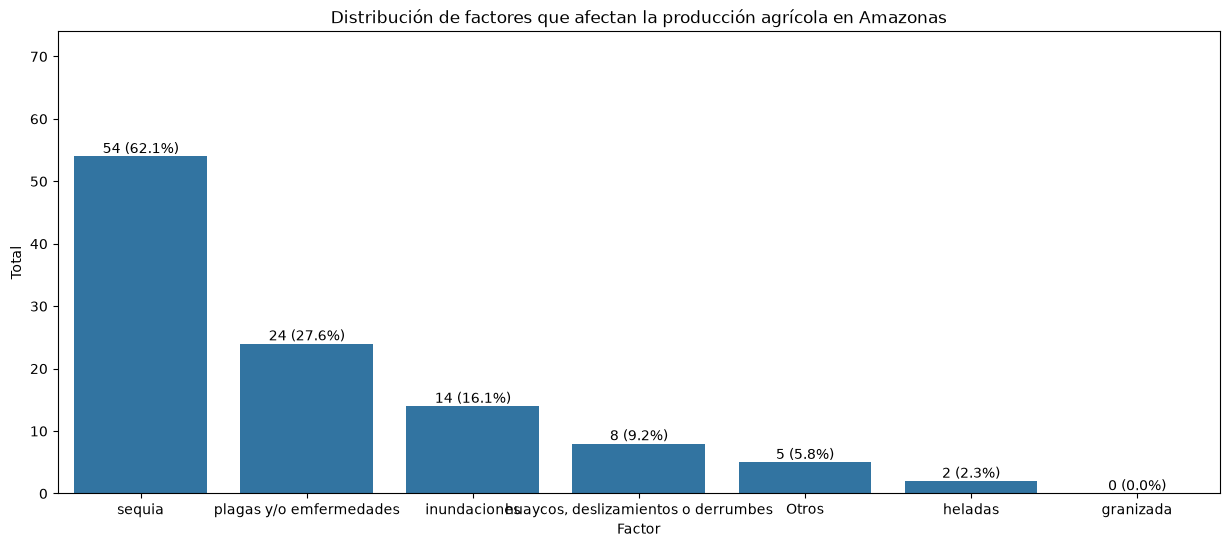

In [87]:
tabla_frecuencias_factores_ama = tabla_ama.sort_values(
    "si_afecto",
    ascending=False
)
plt.figure(figsize = (15,6))

g_ama_fac = sns.barplot(
    data = tabla_frecuencias_factores_ama, 
    x = "factor",
    y = "si_afecto" 
)

for i, barra in enumerate(g_ama_fac.patches): 
    conteo = tabla_frecuencias_factores_ama["si_afecto"].iloc[i]
    porcentaje = tabla_frecuencias_factores_ama["porcentaje_falla"].iloc[i]

    g_ama_fac.text(
        barra.get_x() + barra.get_width()/ 2,
        barra.get_height(), 
        f"{conteo} ({ porcentaje:.1f}%)",
        ha = "center", 
        va= "bottom"
    )
plt.ylim(0, tabla_frecuencias_factores_ama["si_afecto"].max()+20)
plt.title("Distribución de factores que afectan la producción agrícola en Amazonas")
plt.xlabel("Factor")
plt.ylabel("Total")
plt.show()

promedio del número de parcela por región o el total de registros

In [125]:
datos["P147"] = pd.to_numeric(df_cap200b["P147"], errors="coerce")

resumen_p147_peru = df_cap200b.groupby("NOMBREDD").agg(
    promedio_parcelas = ("P147", "mean"),  # Promedio
    total_registros = ("P147", "size")     # total
).reset_index().round(2)

peru_p147_merge = peru.merge(
    resumen_p147_peru,
    left_on="NOMBDEP",
    right_on="NOMBREDD",
    how="left"
).copy()

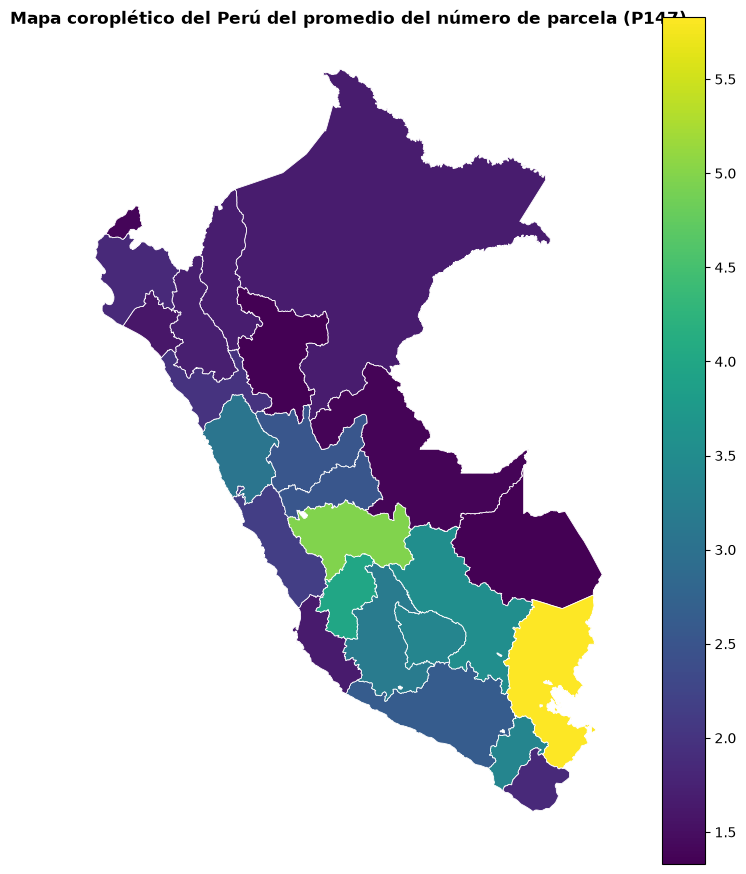

In [126]:
peru_p147_merge = peru.merge(
    resumen_p147_peru,
    left_on="NOMBDEP",
    right_on="NOMBREDD",
    how="left"
).copy()

fig, ax = plt.subplots(figsize=(9, 11))

peru_p147_merge.plot(
    column="promedio_parcelas",  
    cmap="viridis",
    legend=True,
    edgecolor="white",
    linewidth=0.6,
    ax=ax
)

ax.set_title("Mapa coroplético del Perú del promedio del número de parcela (P147)", fontsize=12, fontweight="bold")
ax.set_axis_off()
plt.show()

Representa la parte entera de la superficie sembrada o instalada.

In [130]:
limpiamos
datos.columns = datos.columns.str.strip()

#  todo sea numerico
datos["P224D_SUP_1"] = pd.to_numeric(datos["P224D_SUP_1"], errors="coerce")

#  Agrupar usando del df
resumen_sup_peru = datos.groupby("NOMBREDD").agg(
    superficie_total = ("P224D_SUP_1", "sum"),
    total_registros = ("P224D_SUP_1", "size")
).reset_index().round(2)

# unimos
peru_sup_merge = peru.merge(
    resumen_sup_peru,
    left_on="NOMBDEP",
    right_on="NOMBREDD",
    how="left"
).copy()

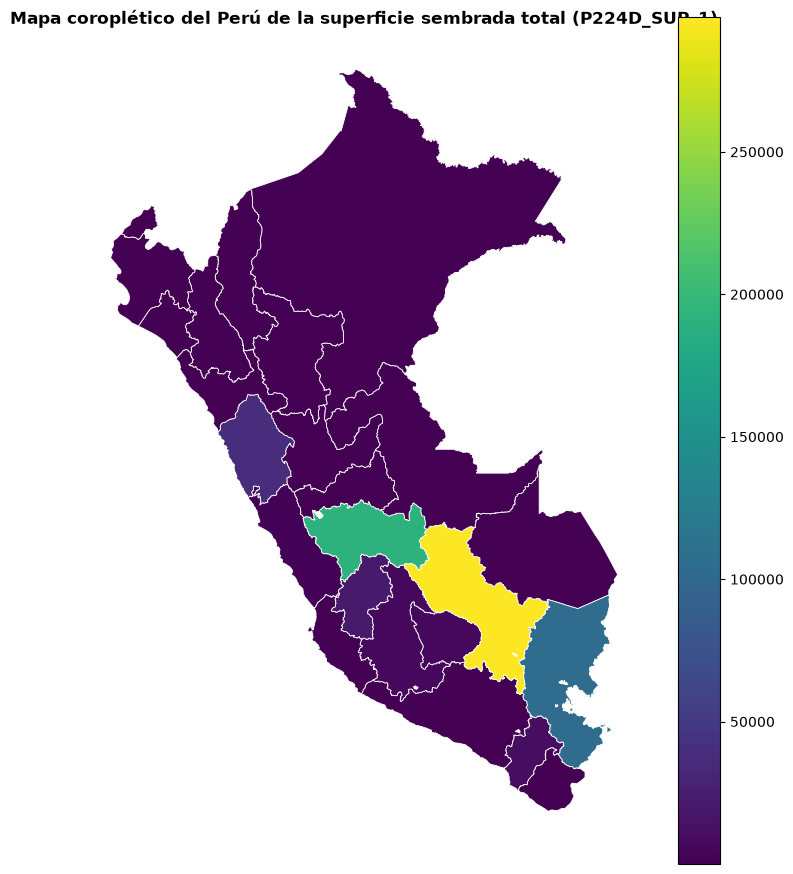

In [132]:
fig, ax = plt.subplots(figsize=(9, 11))

peru_sup_merge.plot(
    column="superficie_total",
    cmap="viridis",             
    legend=True,
    edgecolor="white",
    linewidth=0.6,
    ax=ax
)

ax.set_title("Mapa coroplético del Perú de la superficie sembrada total (P224D_SUP_1)", fontsize=12, fontweight="bold")
ax.set_axis_off()
plt.show()